# 8장. 가상계측 모델 개발

「AI로 만드는 제조공정 품질관리 따라하기」 8장 실습 Notebook입니다.
평가 규칙: training 세트 안에서 웨이퍼 단위 GroupKFold(5겹)로 비교하고,
공식 validation + test(정답 공개분, 848건)는 마지막에 평가용으로만 씁니다.

In [1]:
import os
import sys
from pathlib import Path

if "google.colab" in sys.modules and not Path("src").exists():
    !git clone -q https://github.com/ady95/manufacturing-ai-tutorial.git
    %cd manufacturing-ai-tutorial/02-virtual-metrology

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
Path("results").mkdir(exist_ok=True)

In [2]:
import json
import platform

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import xgboost
from sklearn.base import clone
from sklearn.cross_decomposition import PLSRegression
from sklearn.decomposition import PCA
from sklearn.inspection import permutation_importance
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from src.cmp_utils import (SEED, build_table, feature_columns, load_cmp, make_models,
                           regression_report, timed)

print("Python", platform.python_version(), "| scikit-learn", sklearn.__version__, "| XGBoost", xgboost.__version__)

Python 3.12.9 | scikit-learn 1.9.1 | XGBoost 3.4.1


## 8-1. 센서 시계열 통계 특징 추출

In [3]:
data = load_cmp()
tabs = {split: build_table(*v) for split, v in data.items()}
train = tabs["train"]
print("training:", train.shape, "| 제거율 1000 초과 제외:", (train["AVG_REMOVAL_RATE"] > 1000).sum(), "건")
train = train[train["AVG_REMOVAL_RATE"] < 1000].reset_index(drop=True)
hold = pd.concat([tabs["val"].assign(split="val"), tabs["test"].assign(split="test")], ignore_index=True)
cols = feature_columns(train)
print("특징 수:", len(cols), "| 평가 데이터:", len(hold))
train[["WAFER_ID", "STAGE", "grp"] + cols[:6] + ["AVG_REMOVAL_RATE"]].head()

training: (1981, 93) | 제거율 1000 초과 제외: 4 건
특징 수: 88 | 평가 데이터: 848


,WAFER_ID,STAGE,grp,duration,n_rows,USAGE_OF_BACKING_FILM_start,USAGE_OF_DRESSER_start,USAGE_OF_POLISHING_TABLE_start,USAGE_OF_DRESSER_TABLE_start,AVG_REMOVAL_RATE
0,-4230160598,A,A456,361.667,346,884.166667,634.444444,202.222222,2734.00,68.88180
1,-4230160594,B,B,368.333,256,1285.833333,658.888889,211.111111,2750.50,70.05330
2,-4230160436,B,B,384.667,359,3266.666667,768.518519,317.777778,2824.50,54.30720
3,-4230160428,A,A456,358.334,342,5918.333333,149.629630,271.111111,2925.75,75.34995
4,-4230160424,A,A456,362.000,344,4864.166667,93.703704,37.777778,2888.00,78.33015


In [4]:
X, y, grp, wafer = train[cols], train["AVG_REMOVAL_RATE"].to_numpy(), train["grp"].to_numpy(), train["WAFER_ID"]
Xh, yh, grph = hold[cols], hold["AVG_REMOVAL_RATE"].to_numpy(), hold["grp"].to_numpy()

pca = make_pipeline(StandardScaler(), PCA()).fit(X)
cum = np.cumsum(pca[-1].explained_variance_ratio_)
pca_n = {f"{int(t*100)}%": int(np.searchsorted(cum, t) + 1) for t in (0.8, 0.9, 0.95, 0.99)}
print("누적 설명 분산에 필요한 주성분 수:", pca_n)

누적 설명 분산에 필요한 주성분 수: {'80%': 9, '90%': 15, '95%': 20, '99%': 33}


In [5]:
corr = X.corr().abs().where(np.triu(np.ones((len(cols), len(cols)), bool), 1))
high = (corr > 0.95).sum().sum()
print("상관계수 절댓값 0.95 초과 특징 쌍:", int(high))

상관계수 절댓값 0.95 초과 특징 쌍: 79


## 8-2. 기준선, Ridge, PLS

In [6]:
gkf = GroupKFold(n_splits=5, shuffle=True, random_state=SEED)
folds = list(gkf.split(X, y, groups=wafer))
results, holdout_pred, fit_sec = {}, {}, {}

def record(name, oof, pred, sec):
    results[name] = {"cv": regression_report(y, oof, grp), "hold": regression_report(yh, pred, grph)}
    holdout_pred[name] = np.ravel(pred)
    fit_sec[name] = sec
    cv, ho = results[name]["cv"].loc["전체"], results[name]["hold"].loc["전체"]
    print(f"{name:14s} CV MAE {cv.MAE:.3f} RMSE {cv.RMSE:.3f} | 평가 MAE {ho.MAE:.3f} RMSE {ho.RMSE:.3f} R2 {ho.R2:.3f}")

# 기준선: 공정 그룹 평균
oof = np.zeros(len(train))
for a, b in folds:
    oof[b] = pd.Series(grp[b]).map(train.iloc[a].groupby("grp")["AVG_REMOVAL_RATE"].mean())
record("GroupMean", oof, pd.Series(grph).map(train.groupby("grp")["AVG_REMOVAL_RATE"].mean()), 0.0)

GroupMean      CV MAE 5.782 RMSE 7.436 | 평가 MAE 5.827 RMSE 7.454 R2 0.935


In [7]:
print(results["GroupMean"]["hold"].round(3))

          n    MAE   RMSE     R2
전체    848.0  5.827  7.454  0.935
A123  140.0  3.071  3.994 -0.011
A456  350.0  5.299  6.663 -0.014
B     358.0  7.422  9.054 -0.003


In [8]:
models = make_models()
oof, sec = timed(cross_val_predict, models["Ridge"], X, y, groups=wafer, cv=folds)
m = clone(models["Ridge"]).fit(X, y)
print("선택된 alpha:", round(float(m[-1].alpha_), 3))
record("Ridge", oof, m.predict(Xh), sec)

선택된 alpha: 3.162
Ridge          CV MAE 4.156 RMSE 5.236 | 평가 MAE 4.275 RMSE 5.803 R2 0.960


In [9]:
# 그룹마다 따로 학습하는 Ridge
class PerGroup:
    def __init__(self, base):
        self.base = base
    def fit(self, X, y, g):
        self.models = {k: clone(self.base).fit(X[g == k], y[g == k]) for k in np.unique(g)}
        return self
    def predict(self, X, g):
        out = np.zeros(len(X))
        for k, mdl in self.models.items():
            if (g == k).any():
                out[g == k] = np.ravel(mdl.predict(X[g == k]))
        return out

oof = np.zeros(len(train))
for a, b in folds:
    oof[b] = PerGroup(models["Ridge"]).fit(X.iloc[a], y[a], grp[a]).predict(X.iloc[b], grp[b])
pg = PerGroup(models["Ridge"]).fit(X, y, grp)
record("Ridge(그룹별)", oof, pg.predict(Xh, grph), 0.0)

Ridge(그룹별)     CV MAE 3.862 RMSE 5.098 | 평가 MAE 4.099 RMSE 8.868 R2 0.907


In [10]:
print(results["Ridge"]["hold"].round(3))
print(results["Ridge(그룹별)"]["hold"].round(3))

          n    MAE   RMSE     R2
전체    848.0  4.275  5.803  0.960
A123  140.0  4.558  5.865 -1.180
A456  350.0  3.942  5.913  0.201
B     358.0  4.490  5.667  0.607
          n    MAE    RMSE     R2
전체    848.0  4.099   8.868  0.907
A123  140.0  2.857   3.757  0.105
A456  350.0  4.355  12.305 -2.460
B     358.0  4.333   5.721  0.600


In [11]:
# PLS 성분 수 선택 (training CV)
pls_cv = {}
for k in [1, 2, 3, 5, 8, 10, 15, 20, 30]:
    pipe = make_pipeline(StandardScaler(), PLSRegression(n_components=k))
    o = np.ravel(cross_val_predict(pipe, X, y, groups=wafer, cv=folds))
    pls_cv[k] = float(np.sqrt(np.mean((o - y) ** 2)))
print({k: round(v, 3) for k, v in pls_cv.items()})
best_rmse = min(pls_cv.values())
# 최저 RMSE의 1% 이내에 드는 가장 작은 성분 수 (단순한 모델 우선)
best_k = min(k for k, v in pls_cv.items() if v <= best_rmse * 1.01)
print("최저 RMSE 성분 수:", min(pls_cv, key=pls_cv.get), "| 선택된 성분 수:", best_k)

pls = make_pipeline(StandardScaler(), PLSRegression(n_components=best_k))
oof, sec = timed(cross_val_predict, pls, X, y, groups=wafer, cv=folds)
record("PLS", np.ravel(oof), np.ravel(clone(pls).fit(X, y).predict(Xh)), sec)

{1: 20.911, 2: 14.933, 3: 13.015, 5: 8.183, 8: 6.324, 10: 5.771, 15: 5.475, 20: 5.294, 30: 5.286}
최저 RMSE 성분 수: 30 | 선택된 성분 수: 20
PLS            CV MAE 4.198 RMSE 5.294 | 평가 MAE 4.283 RMSE 5.703 R2 0.962


## 8-3. Random Forest와 XGBoost 회귀

In [12]:
for name in ["RandomForest", "XGBoost"]:
    oof, sec = timed(cross_val_predict, models[name], X, y, groups=wafer, cv=folds)
    fitted = clone(models[name]).fit(X, y)
    record(name, oof, fitted.predict(Xh), sec)
    if name == "XGBoost":
        xgb_model = fitted

RandomForest   CV MAE 2.708 RMSE 3.540 | 평가 MAE 2.497 RMSE 3.353 R2 0.987


XGBoost        CV MAE 2.615 RMSE 3.451 | 평가 MAE 2.529 RMSE 3.374 R2 0.987


In [13]:
gain = pd.Series(xgb_model.feature_importances_, index=cols).sort_values(ascending=False)
print("XGBoost 내장 중요도 상위 8:")
print(gain.head(8).round(3))

XGBoost 내장 중요도 상위 8:
grp_A123                          0.934
n_rows                            0.016
duration                          0.013
SLURRY_FLOW_LINE_C_mean           0.009
stage_B                           0.005
USAGE_OF_DRESSER_TABLE_start      0.002
CENTER_AIR_BAG_PRESSURE_active    0.002
USAGE_OF_DRESSER_start            0.001
dtype: float32


In [14]:
perm = permutation_importance(xgb_model, Xh, yh, scoring="neg_mean_absolute_error",
                              n_repeats=10, random_state=SEED)
perm_s = pd.Series(perm.importances_mean, index=cols).sort_values(ascending=False)
print("평가 데이터 순열 중요도(MAE 증가량) 상위 10:")
print(perm_s.head(10).round(3))

평가 데이터 순열 중요도(MAE 증가량) 상위 10:
grp_A123                          14.315
stage_B                            2.171
USAGE_OF_DRESSER_TABLE_start       1.990
duration                           1.791
n_rows                             1.408
USAGE_OF_DRESSER_start             1.297
SLURRY_FLOW_LINE_A_active          0.182
USAGE_OF_POLISHING_TABLE_start     0.151
USAGE_OF_BACKING_FILM_start        0.137
CENTER_AIR_BAG_PRESSURE_active     0.090
dtype: float64


## 8-4. 실제 계측값과 예측값 비교

In [15]:
rows = []
for name, r in results.items():
    for part in ["전체", "A123", "A456", "B"]:
        rows.append({"model": name, "part": part,
                     "cv_MAE": r["cv"].loc[part, "MAE"], "MAE": r["hold"].loc[part, "MAE"],
                     "RMSE": r["hold"].loc[part, "RMSE"], "R2": r["hold"].loc[part, "R2"]})
table = pd.DataFrame(rows)
print(table.pivot(index="model", columns="part", values="MAE").round(3))
print(table.pivot(index="model", columns="part", values="R2").round(3))

part           A123   A456      B     전체
model                                   
GroupMean     3.071  5.299  7.422  5.827
PLS           4.645  3.906  4.510  4.283
RandomForest  2.384  2.183  2.849  2.497
Ridge         4.558  3.942  4.490  4.275
Ridge(그룹별)    2.857  4.355  4.333  4.099
XGBoost       2.615  2.490  2.534  2.529
part           A123   A456      B     전체
model                                   
GroupMean    -0.011 -0.014 -0.003  0.935
PLS          -1.253  0.286  0.601  0.962
RandomForest  0.419  0.800  0.823  0.987
Ridge        -1.180  0.201  0.607  0.960
Ridge(그룹별)    0.105 -2.460  0.600  0.907
XGBoost       0.264  0.739  0.862  0.987


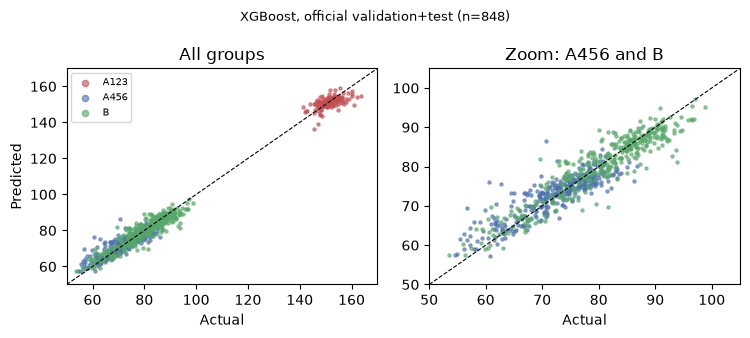

In [16]:
colors = {"A123": "#C44E52", "A456": "#4C72B0", "B": "#55A868"}
p = holdout_pred["XGBoost"]
fig, axes = plt.subplots(1, 2, figsize=(7.6, 3.4))
for gname in ["A123", "A456", "B"]:
    mm = grph == gname
    axes[0].scatter(yh[mm], p[mm], s=5, alpha=0.6, color=colors[gname], label=gname)
lim = [50, 170]
axes[0].plot(lim, lim, "k--", lw=0.8)
axes[0].set(xlim=lim, ylim=lim, xlabel="Actual", ylabel="Predicted", title="All groups")
axes[0].legend(fontsize=7, markerscale=2)
mm = grph != "A123"
for gname in ["A456", "B"]:
    m2 = grph == gname
    axes[1].scatter(yh[m2], p[m2], s=5, alpha=0.6, color=colors[gname], label=gname)
lim2 = [50, 105]
axes[1].plot(lim2, lim2, "k--", lw=0.8)
axes[1].set(xlim=lim2, ylim=lim2, xlabel="Actual", title="Zoom: A456 and B")
fig.suptitle("XGBoost, official validation+test (n=848)", fontsize=9)
fig.tight_layout()
fig.savefig("results/08_actual_vs_pred.png", dpi=150)
plt.show()

In [17]:
res = yh - p
print("XGBoost 평가 잔차: 평균 {:.3f}, 표준편차 {:.3f}".format(res.mean(), res.std()))
for t in [3, 5, 10]:
    print(f"|오차| > {t}: {(np.abs(res) > t).mean():.3f}")

XGBoost 평가 잔차: 평균 -0.161, 표준편차 3.370
|오차| > 3: 0.325
|오차| > 5: 0.117
|오차| > 10: 0.011


In [18]:
# 큰 오차 사례: 그룹별 Ridge의 최대 오차
pr = holdout_pred["Ridge(그룹별)"]
worst = hold.assign(pred=pr, err=pr - yh).reindex(columns=["split", "grp", "n_rows", "duration", "AVG_REMOVAL_RATE", "pred", "err"])
worst = worst.reindex(worst["err"].abs().sort_values(ascending=False).index)
print(worst.head(5).round(2))
print("training 세트 행 수 최댓값:", int(train["n_rows"].max()), "| 소요 시간 최댓값(초):", round(float(train["duration"].max()), 1))
i_long = int(hold["n_rows"].idxmax())
long_case = {name: round(float(holdout_pred[name][i_long]), 2) for name in holdout_pred}
print("가장 긴 기록(행", int(hold.loc[i_long, "n_rows"]), ") 실제값", round(float(yh[i_long]), 2), "| 모델별 예측:", long_case)

    split   grp  n_rows  duration  AVG_REMOVAL_RATE    pred     err
726  test  A456   14678  29345.33             72.66 -139.38 -212.04
472  test     B     344    373.00             77.22  103.91   26.69
628  test     B     339    357.33             86.06  105.79   19.73
463  test     B     360    376.67             71.69   91.04   19.35
449  test  A456     322    341.00             62.75   81.49   18.74
training 세트 행 수 최댓값: 5492 | 소요 시간 최댓값(초): 29310.7
가장 긴 기록(행 14678 ) 실제값 72.66 | 모델별 예측: {'GroupMean': 73.08, 'Ridge': 5.54, 'Ridge(그룹별)': -139.38, 'PLS': 16.62, 'RandomForest': 73.38, 'XGBoost': 81.54}


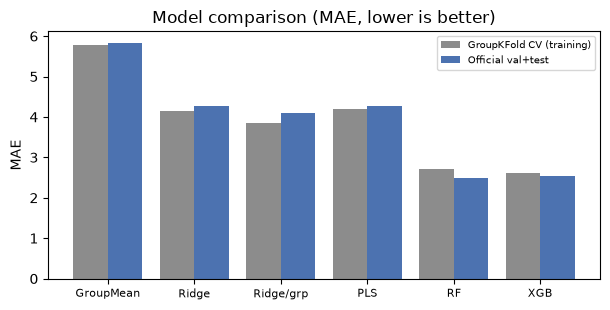

In [19]:
fig, ax = plt.subplots(figsize=(6.2, 3.2))
names = list(results)
cvm = [results[n]["cv"].loc["전체", "MAE"] for n in names]
hom = [results[n]["hold"].loc["전체", "MAE"] for n in names]
xx = np.arange(len(names))
ax.bar(xx - 0.2, cvm, 0.4, label="GroupKFold CV (training)", color="#8C8C8C")
ax.bar(xx + 0.2, hom, 0.4, label="Official val+test", color="#4C72B0")
ax.set_xticks(xx, ["GroupMean", "Ridge", "Ridge/grp", "PLS", "RF", "XGB"], fontsize=8)
ax.set_ylabel("MAE")
ax.set_title("Model comparison (MAE, lower is better)")
ax.legend(fontsize=7)
fig.tight_layout()
fig.savefig("results/08_model_mae.png", dpi=150)
plt.show()

In [20]:
def rep(df):
    return {k: {m: round(float(v), 3) for m, v in row.items()} for k, row in df.iterrows()}

result = {
    "n_features": len(cols), "n_train": int(len(train)), "n_hold": int(len(hold)),
    "pca_components": pca_n, "corr_pairs_gt_095": int(high),
    "ridge_alpha": round(float(m[-1].alpha_), 3),
    "pls_cv_rmse": {str(k): round(v, 3) for k, v in pls_cv.items()}, "pls_best_k": int(best_k),
    "models": {n: {"cv": rep(r["cv"]), "hold": rep(r["hold"]), "cv_sec": round(fit_sec[n], 1)} for n, r in results.items()},
    "xgb_gain_top": gain.head(8).round(3).to_dict(),
    "xgb_perm_top": perm_s.head(10).round(3).to_dict(),
    "xgb_resid": {"mean": round(float(res.mean()), 3), "std": round(float(res.std()), 3),
                  "gt3": round(float((np.abs(res) > 3).mean()), 3), "gt5": round(float((np.abs(res) > 5).mean()), 3),
                  "gt10": round(float((np.abs(res) > 10).mean()), 3)},
    "worst_ridge_grp": worst.head(3).round(2).astype(str).to_dict("records"),
    "train_max_rows": int(train["n_rows"].max()),
    "long_case": {"actual": round(float(yh[i_long]), 2), "pred": long_case},
}
Path("results/08_models.json").write_text(json.dumps(result, ensure_ascii=False, indent=2), encoding="utf-8")
np.save("results/08_holdout_xgb.npy", holdout_pred["XGBoost"])
print(json.dumps({n: v["hold"]["전체"] for n, v in result["models"].items()}, ensure_ascii=False, indent=1))

{
 "GroupMean": {
  "n": 848.0,
  "MAE": 5.827,
  "RMSE": 7.454,
  "R2": 0.935
 },
 "Ridge": {
  "n": 848.0,
  "MAE": 4.275,
  "RMSE": 5.803,
  "R2": 0.96
 },
 "Ridge(그룹별)": {
  "n": 848.0,
  "MAE": 4.099,
  "RMSE": 8.868,
  "R2": 0.907
 },
 "PLS": {
  "n": 848.0,
  "MAE": 4.283,
  "RMSE": 5.703,
  "R2": 0.962
 },
 "RandomForest": {
  "n": 848.0,
  "MAE": 2.497,
  "RMSE": 3.353,
  "R2": 0.987
 },
 "XGBoost": {
  "n": 848.0,
  "MAE": 2.529,
  "RMSE": 3.374,
  "R2": 0.987
 }
}
